
# AI Quant Research Lab
## Stage 7: Machine-Learning Experiment

Objective:
Test whether historical price-based features can predict
the next trading session's direction.

Model: Logistic Regression
Asset: AAPL
Training period: 2021–2023
Out-of-sample test period: 2024–2025

Research safeguards:
- Chronological train/test split
- Features use historical information only
- No random shuffling
- Compare against simple baselines
- Include transaction costs in strategy evaluation


In [22]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    roc_auc_score,
    confusion_matrix
)

# --------------------------------------------------
# 1. Download historical data
# --------------------------------------------------

raw = yf.download(
    "AAPL",
    start="2021-01-01",
    end="2026-01-01",
    auto_adjust=False,
    progress=False
)

if raw.empty:
    raise ValueError("No data downloaded. Check your connection.")

if isinstance(raw.columns, pd.MultiIndex):
    raw.columns = raw.columns.get_level_values(0)

raw = raw.loc[:, ~raw.columns.duplicated()].sort_index()

if "Adj Close" not in raw.columns:
    raise ValueError("Adjusted Close is missing from downloaded data.")

prices = raw["Adj Close"].rename("Price").dropna()

# --------------------------------------------------
# 2. Construct historical features
# --------------------------------------------------

df = pd.DataFrame(index=prices.index)

daily_return = prices.pct_change(fill_method=None)

# Recent momentum
df["return_1d"] = daily_return
df["return_5d"] = prices.pct_change(5, fill_method=None)
df["return_10d"] = prices.pct_change(10, fill_method=None)
df["return_20d"] = prices.pct_change(20, fill_method=None)

# Recent volatility
df["volatility_10d"] = daily_return.rolling(10).std()
df["volatility_20d"] = daily_return.rolling(20).std()

# Price relative to moving averages
sma_20 = prices.rolling(20).mean()
sma_50 = prices.rolling(50).mean()

df["price_vs_sma20"] = prices / sma_20 - 1
df["sma20_vs_sma50"] = sma_20 / sma_50 - 1

# Target: will the NEXT trading session's return be positive?
df["next_return"] = daily_return.shift(-1)
df["target"] = (df["next_return"] > 0).astype(int)

# The final row has no known next-session return.
df.loc[df["next_return"].isna(), "target"] = np.nan

features = [
    "return_1d",
    "return_5d",
    "return_10d",
    "return_20d",
    "volatility_10d",
    "volatility_20d",
    "price_vs_sma20",
    "sma20_vs_sma50"
]

# Remove rows without sufficient historical feature data or target
df = df.dropna(subset=features + ["next_return", "target"]).copy()
df["target"] = df["target"].astype(int)

print("Dataset prepared.")
print("Observations:", len(df))
print("Features:", features)
display(df.head())


Dataset prepared.
Observations: 1205
Features: ['return_1d', 'return_5d', 'return_10d', 'return_20d', 'volatility_10d', 'volatility_20d', 'price_vs_sma20', 'sma20_vs_sma50']


,return_1d,return_5d,return_10d,return_20d,volatility_10d,volatility_20d,price_vs_sma20,sma20_vs_sma50,next_return,target
Date,,,,,,,,,,
2021-03-16,0.012743,0.036997,0.003597,-0.057211,0.024773,0.024312,0.014142,-0.045891,-0.006451,0
2021-03-17,-0.006451,0.039840,0.022120,-0.046469,0.023361,0.024076,0.010080,-0.047579,-0.033905,0
2021-03-18,-0.033905,-0.011725,0.003330,-0.070773,0.025531,0.025079,-0.020527,-0.049611,-0.004480,0
2021-03-19,-0.004480,-0.008593,-0.011777,-0.076076,0.025314,0.025057,-0.020985,-0.052486,0.028336,1
2021-03-22,0.028336,-0.004839,0.060416,-0.020714,0.022283,0.025235,0.007829,-0.052421,-0.006889,0


In [23]:

# --------------------------------------------------
# 3. Chronological train/test split
# --------------------------------------------------

X = df[features]
y = df["target"]

train_mask = df.index < "2024-01-01"
test_mask = df.index >= "2024-01-01"

X_train = X.loc[train_mask]
y_train = y.loc[train_mask]

X_test = X.loc[test_mask]
y_test = y.loc[test_mask]

if len(X_train) == 0 or len(X_test) == 0:
    raise ValueError("Training or test set is empty.")

print("Training:", X_train.index.min().date(),
      "to", X_train.index.max().date())
print("Training observations:", len(X_train))

print("\nTesting:", X_test.index.min().date(),
      "to", X_test.index.max().date())
print("Test observations:", len(X_test))

# --------------------------------------------------
# 4. Build and train logistic regression
# --------------------------------------------------

model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight=None
    ))
])

model.fit(X_train, y_train)

# Predictions for unseen dates
predictions = model.predict(X_test)
probabilities = model.predict_proba(X_test)[:, 1]

print("\nModel training complete.")


Training: 2021-03-16 to 2023-12-29
Training observations: 704

Testing: 2024-01-02 to 2025-12-30
Test observations: 501

Model training complete.


In [24]:

# --------------------------------------------------
# 5. Compare against simple prediction baselines
# --------------------------------------------------

majority_class = int(y_train.mean() >= 0.5)

# Baseline 1: always predict the training majority class
majority_predictions = np.full(
    len(y_test), majority_class
)

# Baseline 2: always predict an up day
always_up_predictions = np.ones(len(y_test), dtype=int)

def evaluate_predictions(name, actual, predicted, probability=None):
    result = {
        "Model": name,
        "Accuracy": accuracy_score(actual, predicted),
        "Balanced Accuracy": balanced_accuracy_score(
            actual, predicted
        ),
        "Precision": precision_score(
            actual, predicted, zero_division=0
        ),
        "Recall": recall_score(
            actual, predicted, zero_division=0
        )
    }

    if probability is not None and actual.nunique() == 2:
        result["ROC AUC"] = roc_auc_score(actual, probability)
    else:
        result["ROC AUC"] = np.nan

    return result

evaluation = pd.DataFrame([
    evaluate_predictions(
        "Logistic Regression", y_test, predictions, probabilities
    ),
    evaluate_predictions(
        "Training Majority Class", y_test, majority_predictions
    ),
    evaluate_predictions(
        "Always Predict Up", y_test, always_up_predictions
    )
]).set_index("Model")

print("PREDICTIVE PERFORMANCE")
display(evaluation.style.format("{:.3f}"))

print("\nLogistic Regression Confusion Matrix")
print(confusion_matrix(y_test, predictions))


PREDICTIVE PERFORMANCE


,Accuracy,Balanced Accuracy,Precision,Recall,ROC AUC
Model,,,,,
Logistic Regression,0.473,0.458,0.514,0.623,0.466
Training Majority Class,0.545,0.500,0.545,1.000,nan
Always Predict Up,0.545,0.500,0.545,1.000,nan



Logistic Regression Confusion Matrix
[[ 67 161]
 [103 170]]


OUT-OF-SAMPLE STRATEGY RESULTS


,ML Strategy,Buy and Hold
Total Return,-0.008206,0.478278
CAGR,-0.004136,0.217268
Annualized Volatility,0.236402,0.278937
Sharpe Ratio (0% risk-free),0.098969,0.842896
Maximum Drawdown,-0.311819,-0.333605


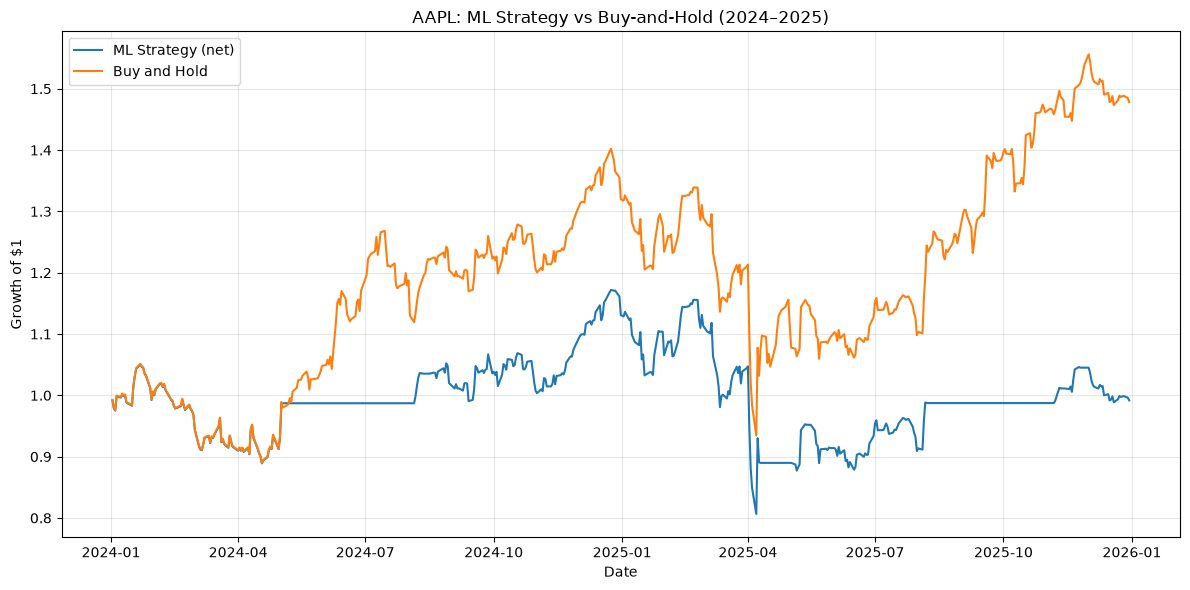

In [25]:

# --------------------------------------------------
# 6. Evaluate a simple prediction-driven strategy
# --------------------------------------------------

# Predictions are made at the close on each test date.
# next_return is the following session's return.
strategy = pd.DataFrame(index=X_test.index)

strategy["Actual_Return"] = df.loc[
    X_test.index, "next_return"
]

strategy["Prediction"] = predictions
strategy["Probability_Up"] = probabilities

# Position held for the NEXT session
strategy["Position"] = strategy["Prediction"].astype(float)

# Turnover measures entries and exits
strategy["Turnover"] = strategy["Position"].diff().abs()

# The first test-period position starts from cash
strategy.iloc[0, strategy.columns.get_loc("Turnover")] = (
    abs(strategy["Position"].iloc[0])
)

transaction_cost = 0.001  # 0.10% per position change

strategy["Strategy_Return"] = (
    strategy["Position"] * strategy["Actual_Return"]
    - strategy["Turnover"] * transaction_cost
)

# Buy-and-hold benchmark over the same target dates
strategy["Buy_Hold_Return"] = strategy["Actual_Return"]

def performance_summary(returns):
    returns = returns.dropna()
    equity = (1 + returns).cumprod()

    total_return = equity.iloc[-1] - 1
    years = len(returns) / 252

    cagr = (
        equity.iloc[-1] ** (1 / years) - 1
        if years > 0 and equity.iloc[-1] > 0
        else np.nan
    )

    volatility = returns.std(ddof=1) * np.sqrt(252)

    sharpe = (
        returns.mean() / returns.std(ddof=1) * np.sqrt(252)
        if returns.std(ddof=1) > 0
        else np.nan
    )

    max_drawdown = (equity / equity.cummax() - 1).min()

    return {
        "Total Return": total_return,
        "CAGR": cagr,
        "Annualized Volatility": volatility,
        "Sharpe Ratio (0% risk-free)": sharpe,
        "Maximum Drawdown": max_drawdown
    }

performance = pd.DataFrame({
    "ML Strategy": performance_summary(
        strategy["Strategy_Return"]
    ),
    "Buy and Hold": performance_summary(
        strategy["Buy_Hold_Return"]
    )
})

print("OUT-OF-SAMPLE STRATEGY RESULTS")
display(performance)

# Plot growth of $1
strategy_equity = (
    1 + strategy["Strategy_Return"]
).cumprod()

buy_hold_equity = (
    1 + strategy["Buy_Hold_Return"]
).cumprod()

plt.figure(figsize=(12, 6))
plt.plot(strategy.index, strategy_equity, label="ML Strategy (net)")
plt.plot(strategy.index, buy_hold_equity, label="Buy and Hold")

plt.title("AAPL: ML Strategy vs Buy-and-Hold (2024–2025)")
plt.xlabel("Date")
plt.ylabel("Growth of $1")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


MODEL COEFFICIENTS


,Feature,Coefficient,Absolute_Importance
7,sma20_vs_sma50,-0.268391,0.268391
6,price_vs_sma20,-0.238930,0.238930
5,volatility_20d,-0.154986,0.154986
2,return_10d,0.121089,0.121089
3,return_20d,0.089276,0.089276
1,return_5d,-0.073719,0.073719
4,volatility_10d,-0.038601,0.038601
0,return_1d,0.037391,0.037391



YEAR-BY-YEAR TEST RESULTS


,ML Total Return,ML Sharpe,ML Max Drawdown,Buy-and-Hold Return,Observations
Year,,,,,
2024,13.09%,0.78,-15.35%,32.00%,252
2025,-12.30%,-0.33,-30.22%,11.99%,249


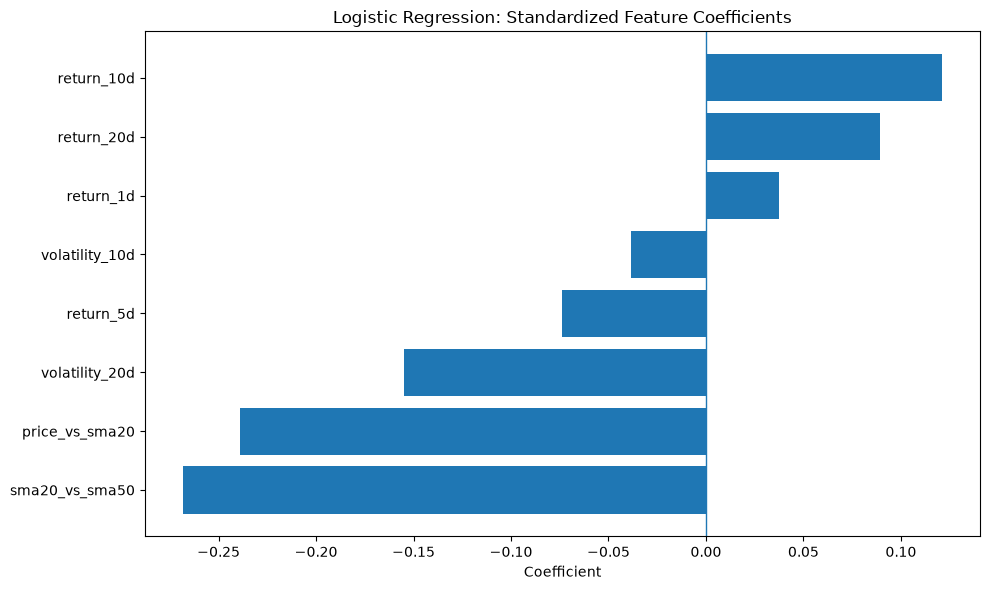

In [26]:

# STAGE 8: MODEL DIAGNOSTICS

# 1. Inspect learned coefficients
classifier = model.named_steps["classifier"]

coefficients = pd.DataFrame({
    "Feature": features,
    "Coefficient": classifier.coef_[0]
})

coefficients["Absolute_Importance"] = (
    coefficients["Coefficient"].abs()
)

coefficients = coefficients.sort_values(
    "Absolute_Importance",
    ascending=False
)

print("MODEL COEFFICIENTS")
display(coefficients)

# Positive coefficients push predictions toward an up day.
# Negative coefficients push predictions toward a down day.
# Because inputs were standardized, magnitudes are more comparable.

# 2. Describe test-period results by calendar year
yearly_results = []

for year, group in strategy.groupby(strategy.index.year):
    metrics = performance_summary(group["Strategy_Return"])
    benchmark = performance_summary(group["Buy_Hold_Return"])

    yearly_results.append({
        "Year": year,
        "ML Total Return": metrics["Total Return"],
        "ML Sharpe": metrics["Sharpe Ratio (0% risk-free)"],
        "ML Max Drawdown": metrics["Maximum Drawdown"],
        "Buy-and-Hold Return": benchmark["Total Return"],
        "Observations": len(group)
    })

yearly_table = pd.DataFrame(yearly_results).set_index("Year")

print("\nYEAR-BY-YEAR TEST RESULTS")
display(yearly_table.style.format({
    "ML Total Return": "{:.2%}",
    "ML Sharpe": "{:.2f}",
    "ML Max Drawdown": "{:.2%}",
    "Buy-and-Hold Return": "{:.2%}"
}))

# 3. Plot coefficient magnitudes and signs
plot_data = coefficients.sort_values("Coefficient")

plt.figure(figsize=(10, 6))
plt.barh(
    plot_data["Feature"],
    plot_data["Coefficient"]
)

plt.axvline(0, linewidth=1)
plt.title("Logistic Regression: Standardized Feature Coefficients")
plt.xlabel("Coefficient")
plt.tight_layout()
plt.show()


In [27]:
print("Available machine-learning results:\n")

for name, value in list(globals().items()):
    if not name.startswith("_") and not callable(value):
        if hasattr(value, "shape"):
            print(f"{name}: shape={value.shape}")

Available machine-learning results:

np: shape=<function shape at 0x107e29bc0>
raw: shape=(1255, 6)
prices: shape=(1255,)
df: shape=(1205, 10)
daily_return: shape=(1255,)
sma_20: shape=(1255,)
sma_50: shape=(1255,)
X: shape=(1205, 8)
y: shape=(1205,)
train_mask: shape=(1205,)
test_mask: shape=(1205,)
X_train: shape=(704, 8)
y_train: shape=(704,)
X_test: shape=(501, 8)
y_test: shape=(501,)
predictions: shape=(501,)
probabilities: shape=(501,)
majority_predictions: shape=(501,)
always_up_predictions: shape=(501,)
evaluation: shape=(3, 5)
strategy: shape=(501, 7)
performance: shape=(5, 2)
strategy_equity: shape=(501,)
buy_hold_equity: shape=(501,)
coefficients: shape=(8, 3)
group: shape=(249, 7)
yearly_table: shape=(2, 5)
plot_data: shape=(8, 3)
result: shape=(2, 5)
daily_strategy: shape=(501, 7)
equity_curves: shape=(501, 2)
confidence_analysis: shape=(4, 4)
actual_up: shape=(501,)
prob_up: shape=(501,)
baseline_probability: shape=()
baseline_predictions: shape=(501,)
test_df: shape=(501

In [28]:
from pathlib import Path

import pandas as pd

# Locate the project reports folder
PROJECT_ROOT = (
    Path.cwd().parent
    if Path.cwd().name == "notebooks"
    else Path.cwd()
)
REPORTS_DIR = PROJECT_ROOT / "reports"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

# Export the actual results from Notebook 03
results_to_export = {
    "ml_evaluation": evaluation,
    "ml_performance": performance,
    "ml_coefficients": coefficients,
    "ml_yearly_performance": yearly_table,
}

for filename, result in results_to_export.items():
    output_path = REPORTS_DIR / f"{filename}.csv"
    result.to_csv(output_path)
    print(f"Saved: {output_path.name} | Shape: {result.shape}")

print("\nNotebook 03 export complete.")

Saved: ml_evaluation.csv | Shape: (3, 5)
Saved: ml_performance.csv | Shape: (5, 2)
Saved: ml_coefficients.csv | Shape: (8, 3)
Saved: ml_yearly_performance.csv | Shape: (2, 5)

Notebook 03 export complete.


In [29]:

from pathlib import Path

PROJECT_ROOT = (
    Path.cwd().parent
    if Path.cwd().name == "notebooks"
    else Path.cwd()
)
OUTPUT_DIR = PROJECT_ROOT / "reports"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Export daily out-of-sample strategy data
daily_strategy = strategy.copy()

daily_strategy.to_csv(
    OUTPUT_DIR / "ml_daily_strategy_returns.csv",
    index=True
)

# Export equity curves if they are available
equity_curves = pd.DataFrame({
    "ML Strategy Equity": strategy_equity,
    "Buy and Hold Equity": buy_hold_equity,
})

equity_curves.to_csv(
    OUTPUT_DIR / "ml_equity_curves.csv",
    index=True
)

print("Daily strategy data exported.")
print("Strategy shape:", daily_strategy.shape)
print("Columns:", daily_strategy.columns.tolist())
print("Equity curves shape:", equity_curves.shape)


Daily strategy data exported.
Strategy shape: (501, 7)
Columns: ['Actual_Return', 'Prediction', 'Probability_Up', 'Position', 'Turnover', 'Strategy_Return', 'Buy_Hold_Return']
Equity curves shape: (501, 2)


In [30]:
print("First test date:", strategy.index.min())
print("Last test date:", strategy.index.max())
print("Number of test sessions:", len(strategy))

print("\nMissing values:")
print(strategy[[
    "Actual_Return",
    "Prediction",
    "Strategy_Return",
    "Buy_Hold_Return"
]].isna().sum())

print("\nDuplicate dates:", strategy.index.duplicated().sum())

First test date: 2024-01-02 00:00:00
Last test date: 2025-12-30 00:00:00
Number of test sessions: 501

Missing values:
Actual_Return      0
Prediction         0
Strategy_Return    0
Buy_Hold_Return    0
dtype: int64

Duplicate dates: 0


In [31]:
print("Prediction distribution:")
print(strategy["Prediction"].value_counts().sort_index())

print("\nFraction of sessions invested:")
print(strategy["Position"].mean())

print("\nNumber of position changes:")
print(int(strategy["Turnover"].sum()))

print("\nAverage next-session return:")
print(strategy["Actual_Return"].mean())

print("\nAverage return when predicting UP:")
print(
    strategy.loc[
        strategy["Prediction"] == 1, "Actual_Return"
    ].mean()
)

print("\nAverage return when predicting DOWN:")
print(
    strategy.loc[
        strategy["Prediction"] == 0, "Actual_Return"
    ].mean()
)

Prediction distribution:
Prediction
0    170
1    331
Name: count, dtype: int64

Fraction of sessions invested:
0.6606786427145709

Number of position changes:
23

Average next-session return:
0.0009329961547732041

Average return when predicting UP:
0.00021001367235973334

Average return when predicting DOWN:
0.00234068557641355


In [32]:
# Group predictions by estimated probability of an upward return
strategy["Confidence_Bucket"] = pd.cut(
    strategy["Probability_Up"],
    bins=[0, 0.4, 0.5, 0.6, 1.0],
    include_lowest=True
)

confidence_analysis = strategy.groupby(
    "Confidence_Bucket",
    observed=False
).agg(
    Sessions=("Actual_Return", "count"),
    Average_Actual_Return=("Actual_Return", "mean"),
    Actual_Up_Rate=(
        "Actual_Return",
        lambda x: (x > 0).mean()
    ),
    Average_Probability_Up=("Probability_Up", "mean")
)

display(confidence_analysis)

,Sessions,Average_Actual_Return,Actual_Up_Rate,Average_Probability_Up
Confidence_Bucket,,,,
"(-0.001, 0.4]",40,0.001607,0.625000,0.358527
"(0.4, 0.5]",130,0.002566,0.600000,0.460349
"(0.5, 0.6]",270,-0.000617,0.514815,0.554633
"(0.6, 1.0]",61,0.003868,0.508197,0.628150


In [33]:
from sklearn.metrics import (
    roc_auc_score,
    brier_score_loss
)

actual_up = (
    strategy["Actual_Return"] > 0
).astype(int)

prob_up = strategy["Probability_Up"]

print(
    "ROC AUC:",
    round(roc_auc_score(actual_up, prob_up), 4)
)

print(
    "Brier score:",
    round(brier_score_loss(actual_up, prob_up), 4)
)

print(
    "Actual positive-return rate:",
    round(actual_up.mean(), 4)
)

print(
    "Mean predicted probability:",
    round(prob_up.mean(), 4)
)

ROC AUC: 0.4661
Brier score: 0.2586
Actual positive-return rate: 0.5449
Mean predicted probability: 0.5235


In [34]:
from sklearn.metrics import brier_score_loss

# Baseline probability estimated from training data only
baseline_probability = y_train.mean()

baseline_predictions = np.full(
    len(y_test),
    baseline_probability,
    dtype=float
)

# Evaluate on the same test dates as the ML model
actual_up = (
    strategy["Actual_Return"] > 0
).astype(int)

model_brier = brier_score_loss(
    actual_up,
    strategy["Probability_Up"]
)

baseline_brier = brier_score_loss(
    actual_up,
    baseline_predictions
)

print(f"Training-set up rate: {baseline_probability:.4f}")
print(f"ML model Brier score: {model_brier:.4f}")
print(f"Baseline Brier score: {baseline_brier:.4f}")
print(f"Brier improvement: {baseline_brier - model_brier:.4f}")

Training-set up rate: 0.5241
ML model Brier score: 0.2586
Baseline Brier score: 0.2484
Brier improvement: -0.0102


In [35]:
# Feature diagnostic on the test period only
feature_names = [
    "return_1d",
    "return_5d",
    "return_10d",
    "return_20d",
    "volatility_10d",
    "volatility_20d",
    "price_vs_sma20",
    "sma20_vs_sma50"
]

diagnostics = []

test_df = df.loc[X_test.index].copy()

for feature in feature_names:
    cutoff = test_df[feature].median()

    low = test_df.loc[
        test_df[feature] <= cutoff, "next_return"
    ]
    high = test_df.loc[
        test_df[feature] > cutoff, "next_return"
    ]

    diagnostics.append({
        "Feature": feature,
        "Low_Group_Count": len(low),
        "High_Group_Count": len(high),
        "Low_Group_Avg_Return": low.mean(),
        "High_Group_Avg_Return": high.mean(),
        "Difference_High_Minus_Low": high.mean() - low.mean()
    })

feature_diagnostics = pd.DataFrame(diagnostics)

display(
    feature_diagnostics.sort_values(
        "Difference_High_Minus_Low",
        ascending=False
    ).reset_index(drop=True)
)

,Feature,Low_Group_Count,High_Group_Count,Low_Group_Avg_Return,High_Group_Avg_Return,Difference_High_Minus_Low
0,volatility_10d,251,250,0.000163,0.001706,0.001543
1,sma20_vs_sma50,251,250,0.000358,0.001511,0.001153
2,volatility_20d,251,250,0.000416,0.001452,0.001037
3,return_20d,251,250,0.000663,0.001205,0.000542
4,return_1d,251,250,0.000845,0.001021,0.000176
5,price_vs_sma20,251,250,0.001073,0.000793,-0.000280
6,return_5d,251,250,0.001517,0.000347,-0.001170
7,return_10d,251,250,0.001604,0.000259,-0.001345


In [36]:

import numpy as np
import pandas as pd
import statsmodels.api as sm

test_df = df.loc[X_test.index].copy()

features_to_test = [
    "volatility_10d",
    "sma20_vs_sma50",
    "return_10d"
]

results = []

for feature in features_to_test:
    median = test_df[feature].median()

    # 1 = high-feature group; 0 = low-feature group
    high_group = (test_df[feature] > median).astype(int)

    regression = sm.OLS(
        test_df["next_return"],
        sm.add_constant(high_group)
    ).fit(
        cov_type="HAC",
        cov_kwds={"maxlags": 5}
    )

    results.append({
        "Feature": feature,
        "Return_Difference": regression.params.iloc[1],
        "HAC_Standard_Error": regression.bse.iloc[1],
        "T_Statistic": regression.tvalues.iloc[1],
        "P_Value": regression.pvalues.iloc[1],
        "CI_Lower": regression.conf_int().iloc[1, 0],
        "CI_Upper": regression.conf_int().iloc[1, 1]
    })

significance_check = pd.DataFrame(results)

display(
    significance_check.style.format({
        "Return_Difference": "{:.6f}",
        "HAC_Standard_Error": "{:.6f}",
        "T_Statistic": "{:.3f}",
        "P_Value": "{:.4f}",
        "CI_Lower": "{:.6f}",
        "CI_Upper": "{:.6f}"
    })
)


,Feature,Return_Difference,HAC_Standard_Error,T_Statistic,P_Value,CI_Lower,CI_Upper
0,volatility_10d,0.001543,0.001518,1.017,0.3093,-0.001432,0.004518
1,sma20_vs_sma50,0.001153,0.001565,0.737,0.4612,-0.001914,0.004220
2,return_10d,-0.001345,0.001455,-0.924,0.3556,-0.004197,0.001508
